In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_error, mean_squared_error

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
model_data = pd.read_csv(
    r"C:\Projek\Machine Learning\portfolio\01\retail-sales-forecasting\data\processed\forecasting_features.csv",
    parse_dates=["date"]
)

model_data.head()

,date,family,sales,day_of_week,day_of_month,month,year,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,2013-01-29,BEVERAGES,40592.0,1,29,1,2013,42178.0,42931.0,46604.0,810.0,50596.857143,55085.714286
1,2013-01-30,BEVERAGES,44583.0,2,30,1,2013,40592.0,43549.0,49122.0,72092.0,50262.714286,56506.500000
2,2013-01-31,BEVERAGES,43078.0,3,31,1,2013,44583.0,38394.0,41646.0,52105.0,50410.428571,55524.035714
3,2013-02-01,BEVERAGES,56866.0,4,1,2,2013,43078.0,46689.0,50245.0,54167.0,51079.571429,55201.642857
4,2013-02-02,BEVERAGES,79804.0,5,2,2,2013,56866.0,69586.0,77014.0,77818.0,52533.428571,55298.035714


In [3]:
model_data = model_data.sort_values(
    ["family", "date"]
).reset_index(drop=True)

print("Dataset shape: ", model_data.shape)
print("Date range: ", model_data['date'].min(), "to", model_data["date"].max())
print("Product families: ", model_data['family'].unique())

Dataset shape:  (8280, 13)
Date range:  2013-01-29 00:00:00 to 2017-08-15 00:00:00
Product families:  <ArrowStringArray>
['BEVERAGES', 'CLEANING', 'DAIRY', 'GROCERY I', 'PRODUCE']
Length: 5, dtype: str


TRAIN-TEST SPLIT
time-based split
training: sampai 8 Agustus 2017
validation: 9-15 Agustus 2017
forecast horizon: 7 hari

In [4]:
cutoff_date = pd.to_datetime("2017-08-08")

train_data = model_data[
    model_data['date'] <= cutoff_date
].copy()

test_data = model_data[
    model_data['date'] > cutoff_date
].copy()

print("Training period: ")
print(train_data['date'].min(), "to", train_data['date'].max())

print("\nValidation period: ")
print(test_data['date'].min(), "to", test_data['date'].max())

print("\nTraining shape: ", train_data.shape)
print("Validation shape: ", test_data.shape)

Training period: 
2013-01-29 00:00:00 to 2017-08-08 00:00:00

Validation period: 
2017-08-09 00:00:00 to 2017-08-15 00:00:00

Training shape:  (8245, 13)
Validation shape:  (35, 13)


BASELINE FORECASTING
a. Naive Forecast: menggunakan penjualan terakhir sebagai prediksi untuk semua hari ke depan. (last_value)
b. Seasonal Naive: menggunakan penjualan pada hari yang sama di minggu sebelumnya. (last_7_values)
c. Moving Average: rata-rata tujuh hari terakhir sebelum periode prediksi, lalu menggunakan angka yang sama untuk tujuh hari ke depan. (last_7_values_mean)

In [5]:
baseline_results = []

for family in model_data["family"].unique():

    family_train = (
        train_data[train_data["family"] == family]
        .sort_values("date")
    )

    family_test = (
        test_data[test_data["family"] == family]
        .sort_values("date")
    )

    last_value = family_train["sales"].iloc[-1]

    last_7_values = family_train["sales"].tail(7).values

    actual = family_test["sales"].values

    for i in range(len(family_test)):

        baseline_results.append({
            "date": family_test["date"].iloc[i],
            "family": family,
            "actual": actual[i],
            "naive": last_value,
            "seasonal_naive": last_7_values[i],
            "moving_average": last_7_values.mean()
        })

baseline_df = pd.DataFrame(baseline_results)

baseline_df.head(10)

,date,family,actual,naive,seasonal_naive,moving_average
0,2017-08-09,BEVERAGES,153010.0,160636.0,204566.0,195072.857143
1,2017-08-10,BEVERAGES,156449.0,160636.0,156806.0,195072.857143
2,2017-08-11,BEVERAGES,189111.0,160636.0,187818.0,195072.857143
3,2017-08-12,BEVERAGES,182318.0,160636.0,225481.0,195072.857143
4,2017-08-13,BEVERAGES,202354.0,160636.0,250784.0,195072.857143
5,2017-08-14,BEVERAGES,174832.0,160636.0,179419.0,195072.857143
6,2017-08-15,BEVERAGES,170773.0,160636.0,160636.0,195072.857143
7,2017-08-09,CLEANING,50985.0,53472.0,90407.0,69556.142857
8,2017-08-10,CLEANING,45205.0,53472.0,68226.0,69556.142857
9,2017-08-11,CLEANING,55682.0,53472.0,61006.0,69556.142857


EVALUATION MODEL BASELINE
a. MAE: rata-rata besarnya kesalahan prediksi.
B. RMSE: memberikan penalti lebih besar pada kesalahan yang ekstrem.
C. WAPE: total absolute error dibandingkan total aktual, dalam persentase.

In [6]:
def evaluate_forecast(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    }

In [7]:
baseline_metrics = []

for method in [
    "naive",
    "seasonal_naive",
    "moving_average"
]:

    metrics = evaluate_forecast(
        baseline_df["actual"],
        baseline_df[method]
    )

    metrics["Model"] = method

    baseline_metrics.append(metrics)

baseline_comparison = pd.DataFrame(baseline_metrics)

baseline_comparison = baseline_comparison[
    ["Model", "MAE", "RMSE", "WAPE (%)"]
]

baseline_comparison.sort_values("WAPE (%)")

,Model,MAE,RMSE,WAPE (%)
0,naive,11888.458212,16283.192246,9.602521
2,moving_average,17301.257877,22987.172023,13.974536
1,seasonal_naive,18375.798090,26297.173362,14.842462


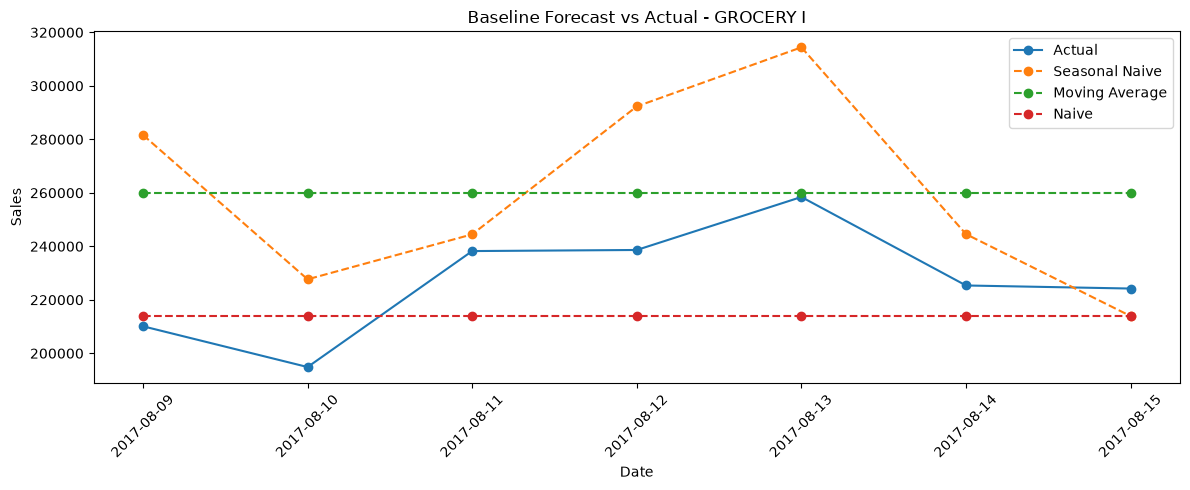

In [8]:
selected_family = "GROCERY I"

plot_data = baseline_df[
    baseline_df["family"] == selected_family
].copy()

plt.figure(figsize=(12, 5))

plt.plot(
    plot_data["date"],
    plot_data["actual"],
    marker="o",
    label="Actual"
)

plt.plot(
    plot_data["date"],
    plot_data["seasonal_naive"],
    marker="o",
    linestyle="--",
    label="Seasonal Naive"
)

plt.plot(
    plot_data["date"],
    plot_data["moving_average"],
    marker="o",
    linestyle="--",
    label="Moving Average"
)

plt.plot(
    plot_data["date"],
    plot_data["naive"],
    marker="o",
    linestyle="--",
    label="Naive"
)

plt.title(f"Baseline Forecast vs Actual - {selected_family}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

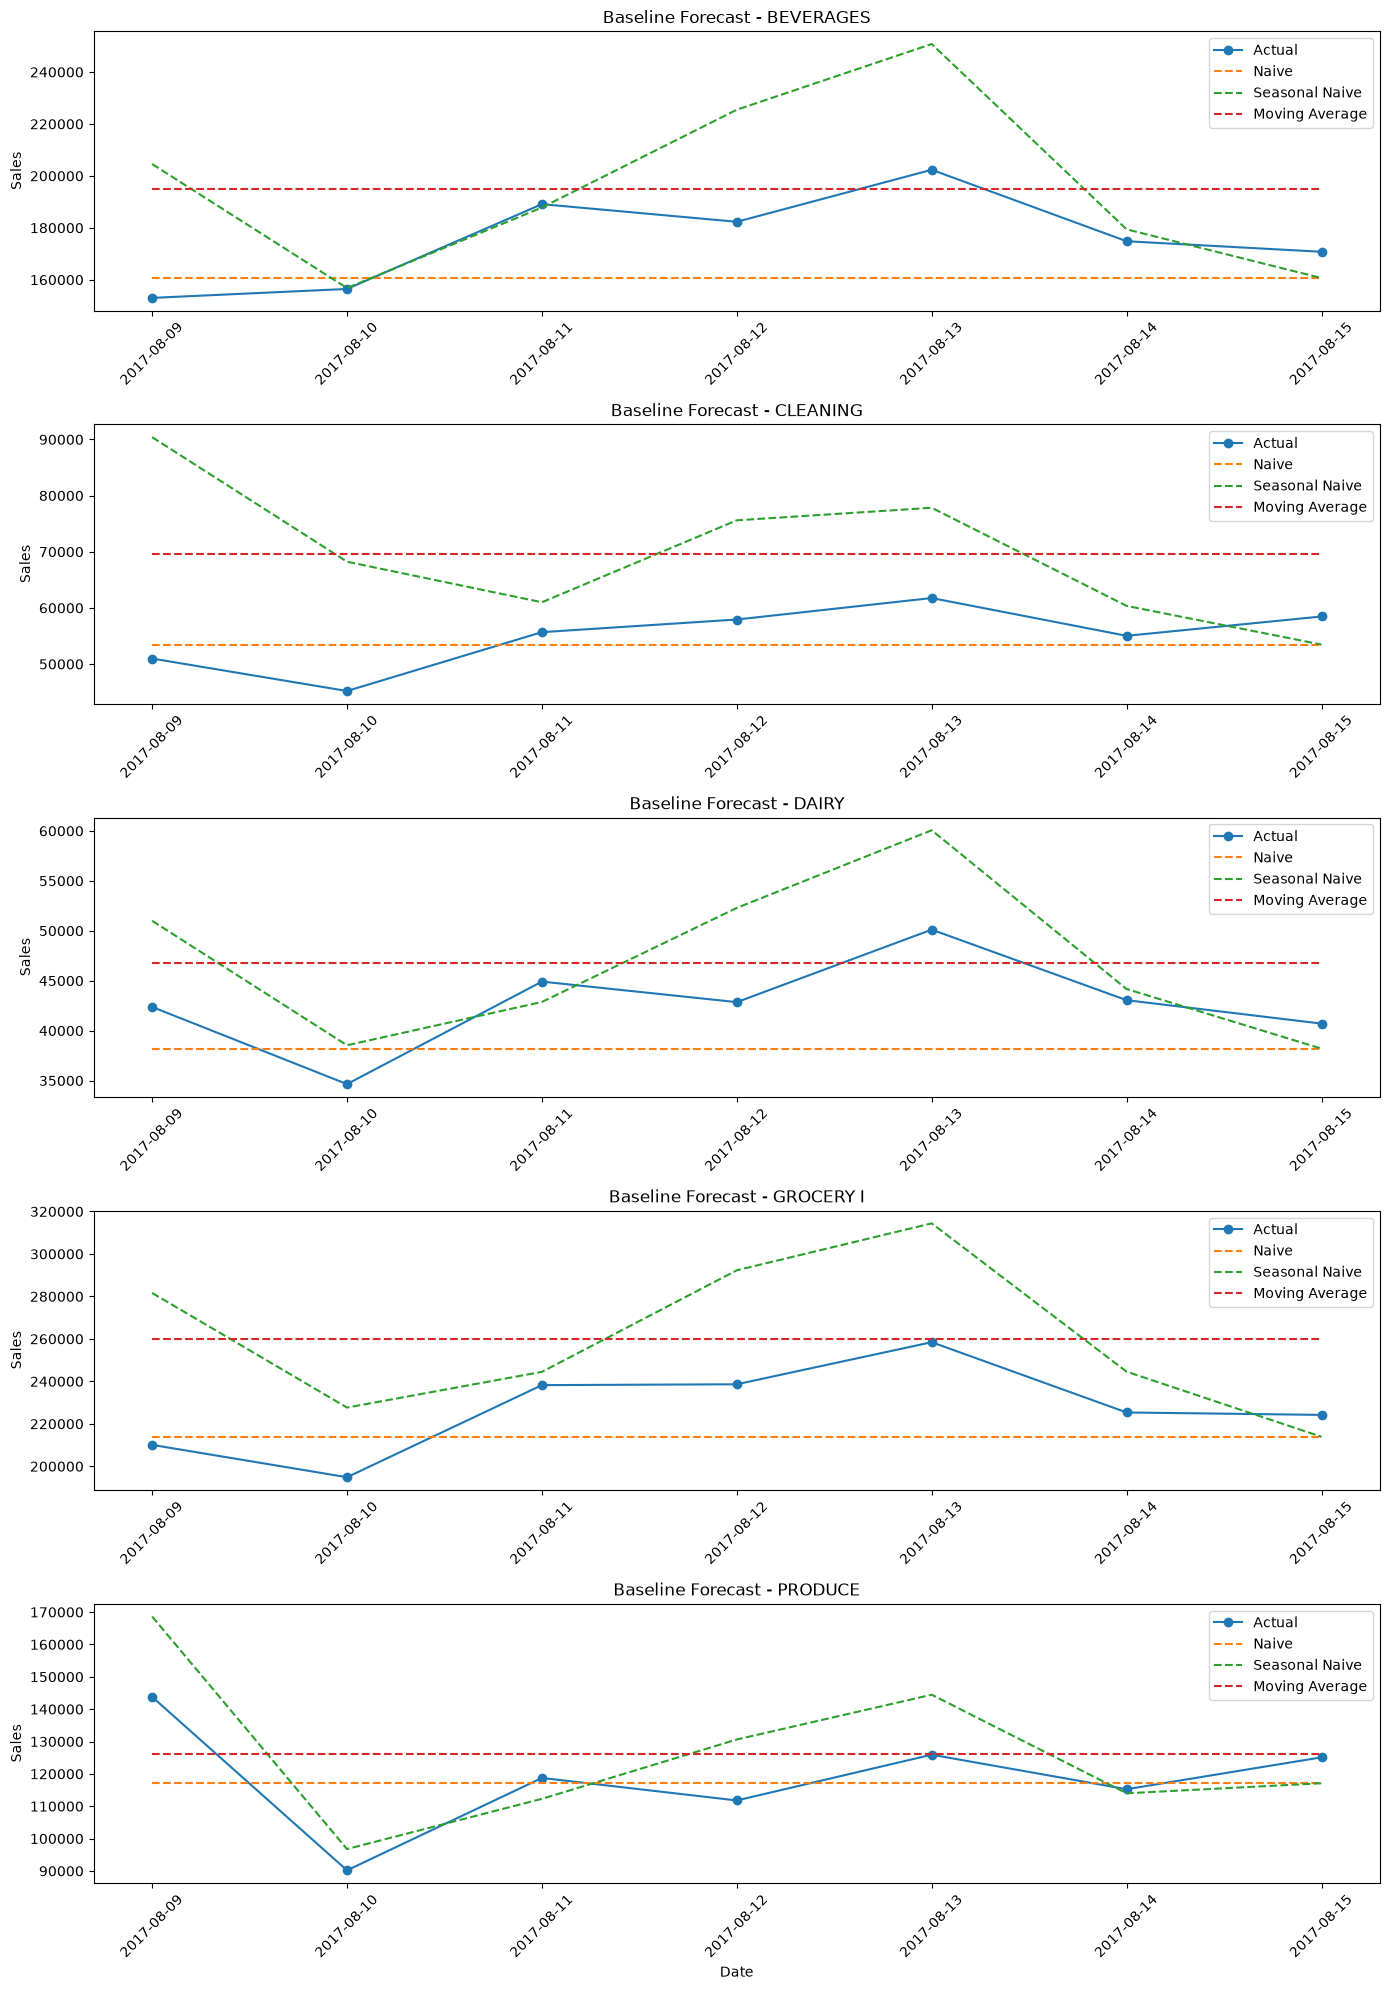

In [9]:
families = baseline_df["family"].unique()

fig, axes = plt.subplots(
    nrows=len(families),
    ncols=1,
    figsize=(14, 20)
)

for ax, family in zip(axes, families):

    plot_data = baseline_df[
        baseline_df["family"] == family
    ].copy()

    ax.plot(
        plot_data["date"],
        plot_data["actual"],
        marker="o",
        label="Actual"
    )

    ax.plot(
        plot_data["date"],
        plot_data["naive"],
        linestyle="--",
        label="Naive"
    )

    ax.plot(
        plot_data["date"],
        plot_data["seasonal_naive"],
        linestyle="--",
        label="Seasonal Naive"
    )

    ax.plot(
        plot_data["date"],
        plot_data["moving_average"],
        linestyle="--",
        label="Moving Average"
    )

    ax.set_title(f"Baseline Forecast - {family}")
    ax.set_ylabel("Sales")
    ax.legend()
    ax.tick_params(axis="x", rotation=45)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()